# Construction Materials Cost Planner: Analysis Notebook

**Course:** C60 Artificial Intelligence: Theory and Applications (Assignment 02)

This notebook explains the analysis done by the two modules of the project:

- **Module 1** (`module1_quantity.py`) calculates the concrete volume and the cement, sand, and aggregate needed for each element and site.
- **Module 2** (`module2_costs.py`) cleans the purchase data, calculates costs, compares required and purchased quantities, tests a price increase, and creates charts and reports.

Run the cells from top to bottom. The notebook must be in the same folder as the code and the three CSV files.

In [1]:
import os
import sys
sys.path.insert(0, os.getcwd())

import pandas as pd
from IPython.display import Image, display

import module1_quantity as m1
import module2_costs as m2

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)

## 1. Load and clean the data

- Elements are loaded by Module 1. Every row passes the same checks as a new element (dimensions greater than zero, waste between 0 and 100, no duplicate ID).
- Prices and purchases are read with pandas. Duplicate transactions are removed, rows with a missing quantity are removed, and every purchase must refer to a known element and a known supplier.
- A missing quantity is removed instead of guessed, because cost = quantity x price, and a guessed quantity would invent a cost.

In [2]:
elements = m1.load_elements("elements.csv")
prices = m2.clean_prices(m2.read_prices("prices.csv"))
raw_purchases = m2.read_purchases("purchases.csv")
purchases = m2.clean_purchases(raw_purchases, m1.existing_ids(elements), set(prices["supplier_id"]))

print("Elements loaded:", len(elements), "| Sites:", sorted(m1.unique_sites(elements)))
print("Purchases before cleaning:", len(raw_purchases))
print("Purchases after cleaning:", len(purchases))
print("Removed:", len(raw_purchases) - len(purchases), "(2 duplicate transactions and 3 missing quantities)")
print()
print("Transactions with a missing quantity:", raw_purchases[raw_purchases["quantity"].isna()]["transaction_id"].tolist())

Elements loaded: 8 | Sites: ['Site A', 'Site B']
Purchases before cleaning: 40
Purchases after cleaning: 35
Removed: 5 (2 duplicate transactions and 3 missing quantities)

Transactions with a missing quantity: ['T012', 'T014', 'T027']


## 2. Module 1: required quantities

Formulas: net volume = length x width x height. Volume with waste = net volume x (1 + waste / 100). For each m3 with waste: 300 kg cement, 0.5 m3 sand, 0.8 m3 aggregate.

In [3]:
m1.print_quantities(elements)
print()
m1.print_site_totals(elements)

E01 | Footing F1 | net 3.75 m3 | with waste 3.94 m3 | cement 1181.25 kg | sand 1.97 m3 | aggregate 3.15 m3
E02 | Column C1 | net 0.48 m3 | with waste 0.50 m3 | cement 149.76 kg | sand 0.25 m3 | aggregate 0.40 m3
E03 | Beam B1 | net 0.90 m3 | with waste 0.94 m3 | cement 283.50 kg | sand 0.47 m3 | aggregate 0.76 m3
E04 | Slab S1 | net 6.00 m3 | with waste 6.36 m3 | cement 1908.00 kg | sand 3.18 m3 | aggregate 5.09 m3
E05 | Footing F2 | net 6.30 m3 | with waste 6.62 m3 | cement 1984.50 kg | sand 3.31 m3 | aggregate 5.29 m3
E06 | Wall W1 | net 7.50 m3 | with waste 8.03 m3 | cement 2407.50 kg | sand 4.01 m3 | aggregate 6.42 m3
E07 | Slab S2 | net 14.40 m3 | with waste 15.26 m3 | cement 4579.20 kg | sand 7.63 m3 | aggregate 12.21 m3
E08 | Column C2 | net 0.88 m3 | with waste 0.91 m3 | cement 273.00 kg | sand 0.46 m3 | aggregate 0.73 m3

Site A | volume 11.74 m3 | cement 3522.51 kg | sand 5.87 m3 | aggregate 9.39 m3
Site B | volume 30.81 m3 | cement 9244.20 kg | sand 15.41 m3 | aggregate 24.6

## 3. Module 2: purchase costs

The purchases are merged with the prices (by supplier ID and material) and with the elements (by element ID, to get the site). Then cost = quantity x unit price. Costs are in the currency of the price file (the file does not name it).

In [4]:
data = m2.add_cost(m2.merge_data(purchases, prices, m2.elements_to_table(elements)))
print("Cost per site");     display(m2.cost_summary(data, "site"))
print("Cost per supplier"); display(m2.cost_summary(data, "supplier_id"))
print("Cost per month");    display(m2.cost_summary(data, "month"))
print("Total cost:", round(data["cost"].sum(), 2))

Purchases without a price: 0
Purchases without a site: 0
Cost per site


,site,cost
0,Site A,712.32
1,Site B,1608.02


Cost per supplier


,supplier_id,cost
0,S01,1668.00
1,S02,652.35


Cost per month


,month,cost
0,2026-08,699.85
1,2026-09,1620.50


Total cost: 2320.35


## 4. Required vs purchased quantities

Required quantities come from Module 1. Purchased quantities come from the cleaned purchases. Units are checked first (cement in kg, sand and aggregate in m3). Difference = purchased - required: below zero is a **Shortage**, above zero is a **Surplus**.

In [5]:
required = m2.required_quantities(elements)
print("Units consistent:", m2.check_units(prices))
comparison = m2.compare_quantities(required, purchases)
display(comparison)
print(comparison["status"].value_counts())

Units consistent: True


,element_id,material,unit,required,purchased,difference,status
0,E01,Cement,kg,1181.25,1040.00,-141.25,Shortage
1,E01,Sand,m3,1.97,2.25,0.28,Surplus
2,E01,Aggregate,m3,3.15,3.35,0.20,Surplus
3,E02,Cement,kg,149.76,70.00,-79.76,Shortage
4,E02,Sand,m3,0.25,0.25,0.00,Exact
5,E02,Aggregate,m3,0.40,0.25,-0.15,Shortage
6,E03,Cement,kg,283.50,290.00,6.50,Surplus
7,E03,Sand,m3,0.47,0.45,-0.02,Shortage
8,E03,Aggregate,m3,0.76,0.85,0.09,Surplus
9,E04,Cement,kg,1908.00,2180.00,272.00,Surplus


status
Shortage    12
Surplus     11
Exact        1
Name: count, dtype: int64


## 5. Price increase scenario (NumPy)

The baseline is the **lowest** price of each material. The user selects one material and a percentage. Only that material's price goes up, and the estimated cost of the **required** quantities is compared before and after.

In [6]:
scenario = m2.price_scenario(required, prices, "Cement", 10)
summary = m2.scenario_summary(scenario)
display(summary)
before = scenario["cost_before"].sum()
after = scenario["cost_after"].sum()
print("Total before:", round(before, 2), "| after:", round(after, 2), "| increase:", round(after - before, 2),
      "(" + str(round((after - before) / before * 100, 1)) + "%)")

,cost_before,cost_after,extra_cost
material,,,
Aggregate,714.94,714.94,0.00
Cement,1404.34,1544.77,140.43
Sand,308.53,308.53,0.00


Total before: 2427.8 | after: 2568.24 | increase: 140.43 (5.8%)


## 6. Charts

The four charts are created by Module 2 and saved as PNG files in the `charts` folder.

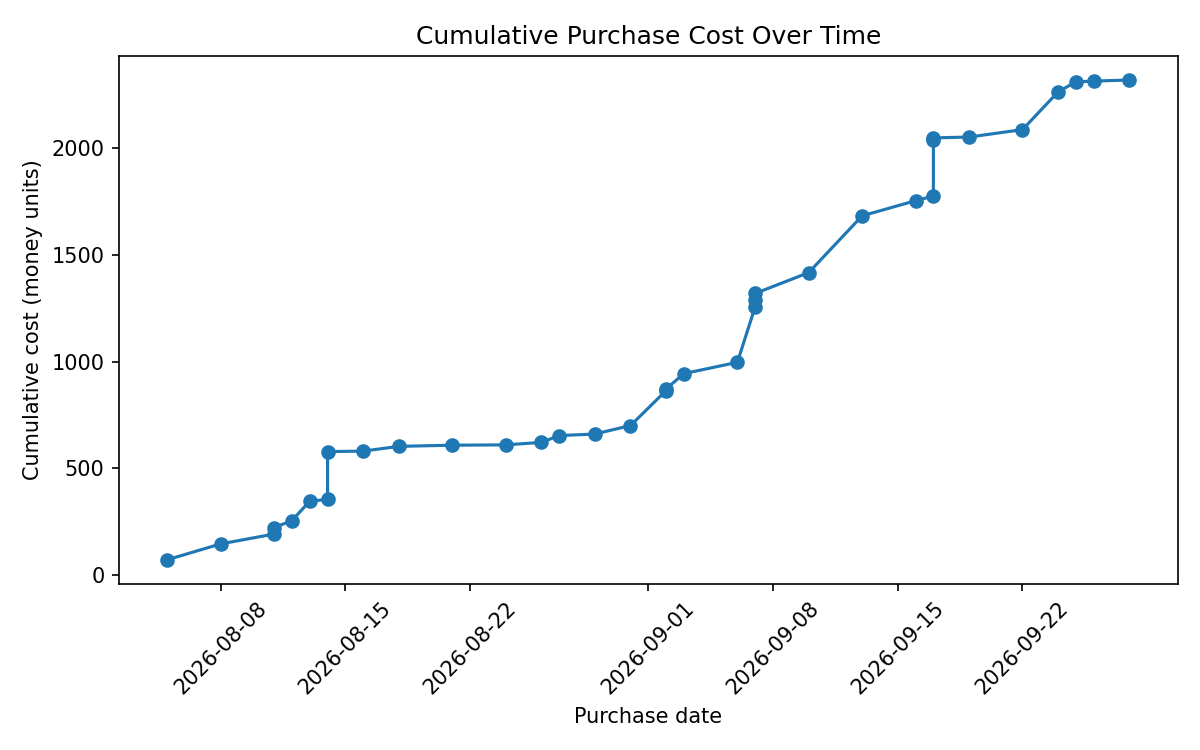

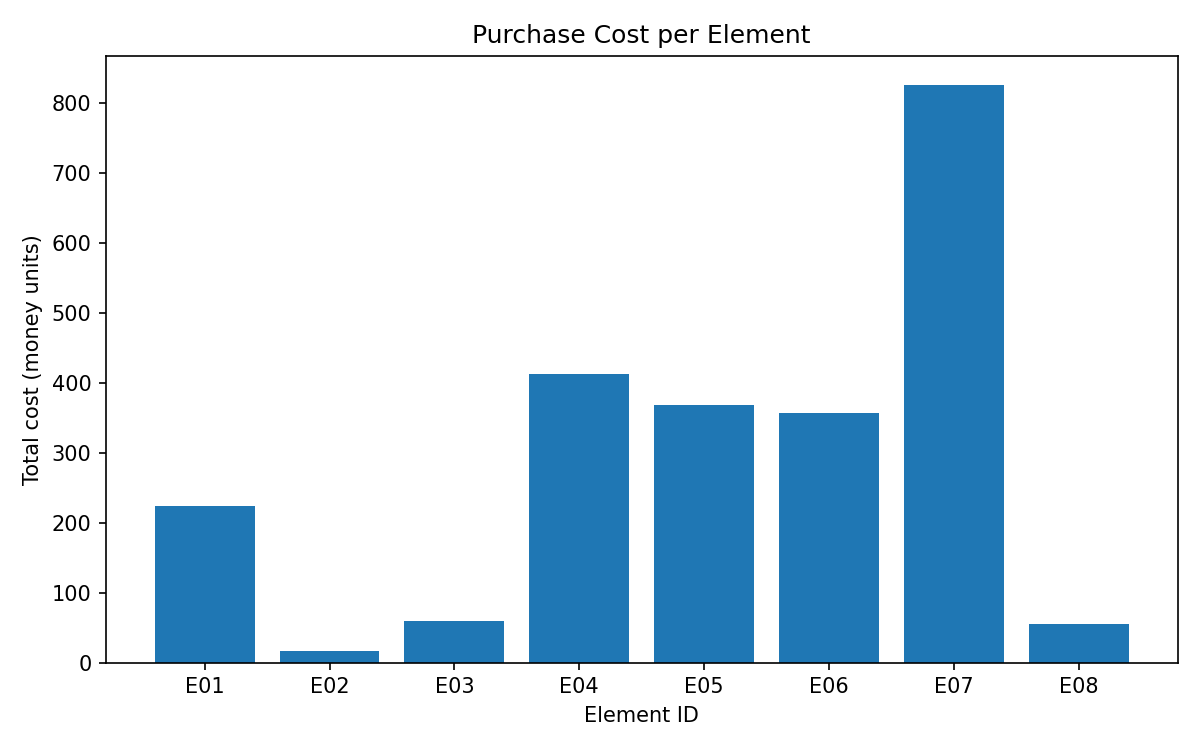

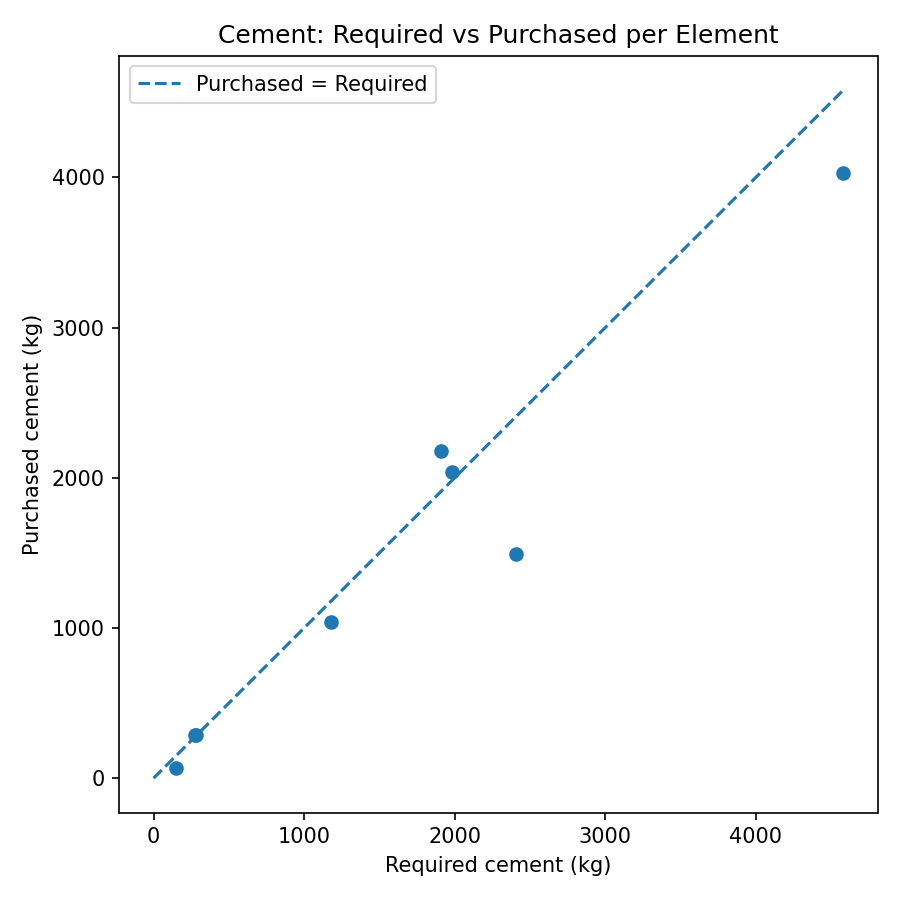

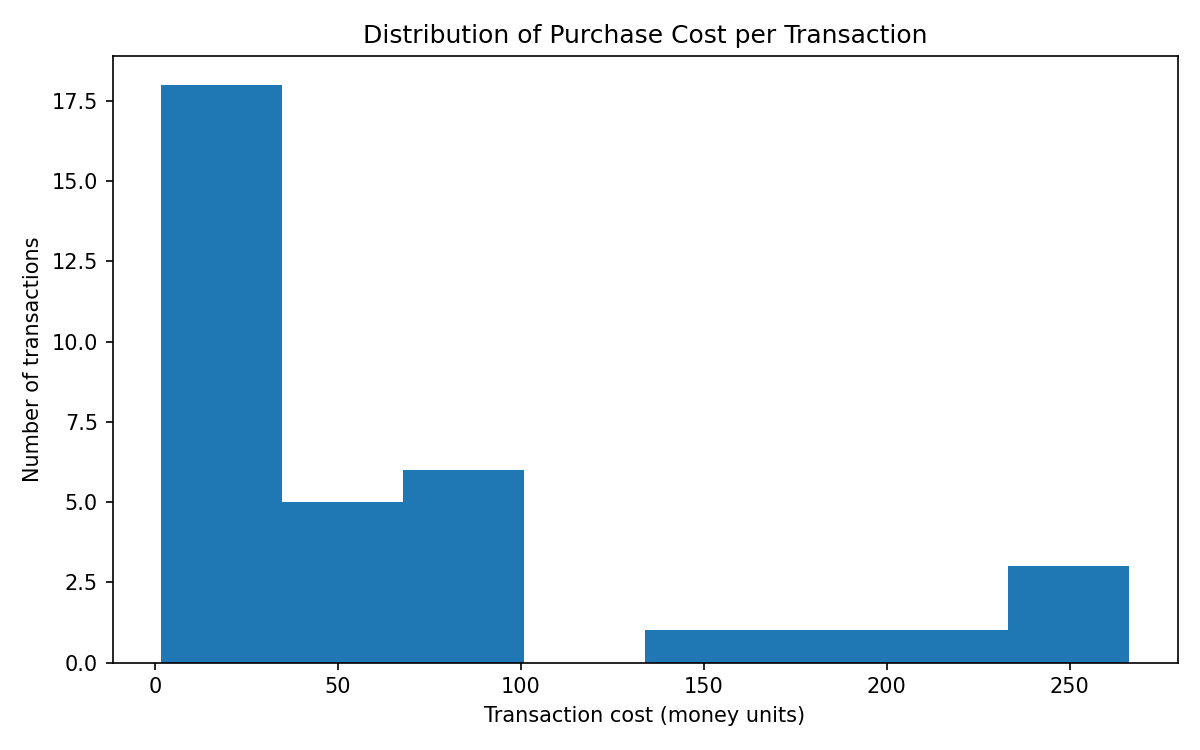

In [7]:
m2.create_charts(data, comparison, "charts")
for name in ["Line_Chart_for_Cost.png", "Bar_Chart_per_Element.png",
             "Scatter_Cement_Required_vs_Purchased.png", "Histogram_Cost.png"]:
    display(Image(filename=os.path.join("charts", name), width=520))

## 7. Tests: 3 valid cases and 3 invalid cases

Each test records the **expected** and the **actual** result.

In [8]:
test_rows = []

def show(value):
    if value is True:
        return "Accepted"
    if value is False:
        return "Rejected"
    return value

def record(kind, test, expected, actual):
    result = "PASS" if expected == actual else "FAIL"
    test_rows.append([kind, test, show(expected), show(actual), result])

test_elements = m1.load_elements("elements.csv")

# Valid cases
record("Valid", "Add element E09 (5.0 x 0.3 x 0.6 m, waste 5%)", True,
       m1.add_element(test_elements, "E09", "Beam B2", "Site B", 5.0, 0.3, 0.6, 5))

e01 = m1.search_element(test_elements, "E01")
record("Valid", "Volume with waste of E01 (2.5 x 2.5 x 0.6 m, waste 5%)", 3.9375,
       round(e01.volume_with_waste(), 4))

original_required = m2.required_quantities(m1.load_elements("elements.csv"))
test_scenario = m2.price_scenario(original_required, prices, "Cement", 10)
extra = m2.scenario_summary(test_scenario).loc["Cement", "extra_cost"]
record("Valid", "Cement price +10%: extra cost of the required quantities", 140.43, round(extra, 2))

# Invalid cases
record("Invalid", "Add element with a duplicate ID (E01)", False,
       m1.add_element(test_elements, "E01", "Copy", "Site A", 1, 1, 1, 5))

record("Invalid", "Add element with a negative length (-2 m)", False,
       m1.add_element(test_elements, "E10", "Bad Slab", "Site A", -2, 1, 1, 5))

bad_purchase = pd.DataFrame({"transaction_id": ["T999"], "element_id": ["E99"], "supplier_id": ["S01"],
                             "material": ["Sand"], "date": ["2026-08-01"], "quantity": [2.0]})
kept = m2.clean_purchases(bad_purchase, m1.existing_ids(test_elements), set(prices["supplier_id"]))
record("Invalid", "Purchase that refers to an unknown element (E99)", 0, len(kept))

results = pd.DataFrame(test_rows, columns=["Type", "Test", "Expected", "Actual", "Result"])
display(results)

Rejected: duplicate ID E01
Rejected: E10 - Dimensions must be greater than zero.


,Type,Test,Expected,Actual,Result
0,Valid,"Add element E09 (5.0 x 0.3 x 0.6 m, waste 5%)",Accepted,Accepted,PASS
1,Valid,"Volume with waste of E01 (2.5 x 2.5 x 0.6 m, w...",3.9375,3.9375,PASS
2,Valid,Cement price +10%: extra cost of the required ...,140.43,140.43,PASS
3,Invalid,Add element with a duplicate ID (E01),Rejected,Rejected,PASS
4,Invalid,Add element with a negative length (-2 m),Rejected,Rejected,PASS
5,Invalid,Purchase that refers to an unknown element (E99),0,0,PASS


## 8. Conclusions

- **Costs:** the total purchase cost is 2320.35. Site B costs more than Site A (1608.02 vs 712.32), supplier S01 more than S02 (1668.00 vs 652.35), and September more than August (1620.50 vs 699.85).
- **Quantities:** of the 24 element-material rows, 12 are shortages, 11 are surpluses, and 1 is exact. The biggest cement shortages are in E06 (-917.50 kg) and E07 (-549.20 kg).
- **Price scenario:** a 10% increase in the cement price adds 140.43 to the estimated cost of the required quantities, about 5.8% of the total (2427.80).
- **Limitation:** 3 transactions (T012, T014, T027) were removed because their quantity is missing, so the purchased quantities of E02 and E06 may be lower than the real ones. The price file also does not state the currency.